<a href="https://colab.research.google.com/github/naubergois/curso-clip-difusao-colab/blob/main/exercicios/aula3-exercicio4-outra-semente.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Aula 3, exercício 4: Outra semente

Gere de novo o mesmo prompt, com semente 4 e 1 passo. A resposta é a imagem. Ela precisa ter 512×512 e não pode ser a mesma `foto_gerada`.

A pergunta usa o que a aula [3. Uma frase vira uma foto](https://colab.research.google.com/github/naubergois/curso-clip-difusao-colab/blob/main/notebooks/03-difusao-texto-para-imagem.ipynb) deixa pronto. **Ambiente de execução → Executar tudo** carrega isso, deixa uma célula para tentar e, no fim, confere uma solução.

In [1]:
import sys
!{sys.executable} -m pip install -q diffusers transformers accelerate matplotlib pillow

## Preparação

A preparação carrega o SD-Turbo e gera o ônibus vermelho na rua de sol, semente 0, dois passos. Ficam prontos `pipe`, `foto_gerada`, `prompt` e a função `gerar`.

In [2]:
import os
import warnings

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
warnings.filterwarnings("ignore", message=".*unauthenticated requests.*")
warnings.filterwarnings("ignore", message=".*torch.jit.script.*")
warnings.filterwarnings("ignore", message=".*local_dir_use_symlinks.*")

import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from diffusers import AutoPipelineForImage2Image, AutoPipelineForText2Image
from diffusers.utils import logging as diffusers_logging
from PIL import Image

diffusers_logging.set_verbosity_error()

MODELO = "stabilityai/sd-turbo"


def baixar(url, destino):
    destino = Path(destino)
    if not destino.exists():
        urllib.request.urlretrieve(url, destino)
    return destino


def dispositivo():
    if torch.cuda.is_available():
        return "cuda", torch.float16
    if torch.backends.mps.is_available():
        return "mps", torch.float32
    return "cpu", torch.float32


def carregar():
    device, dtype = dispositivo()
    extra = {"variant": "fp16"} if device == "cuda" else {}
    try:
        pipe = AutoPipelineForText2Image.from_pretrained(MODELO, dtype=dtype, **extra)
    except TypeError:
        pipe = AutoPipelineForText2Image.from_pretrained(MODELO, torch_dtype=dtype, **extra)
    pipe = pipe.to(device)
    pipe.set_progress_bar_config(disable=True)
    if device == "cpu":
        print("CPU: cada imagem pode levar alguns minutos. No Colab, troque o ambiente para T4.")
    print("dispositivo:", device)
    return pipe


def grade(imagens, titulos):
    n = len(imagens)
    plt.figure(figsize=(3.1 * n, 3.4))
    for i, (img, titulo) in enumerate(zip(imagens, titulos)):
        plt.subplot(1, n, i + 1)
        plt.imshow(img)
        plt.title(titulo, fontsize=9)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


pipe = carregar()


def gerar(texto, semente=0, n_passos=2):
    g = torch.Generator(device="cpu").manual_seed(semente)
    return pipe(
        texto,
        num_inference_steps=n_passos,
        guidance_scale=0.0,
        generator=g,
    ).images[0]

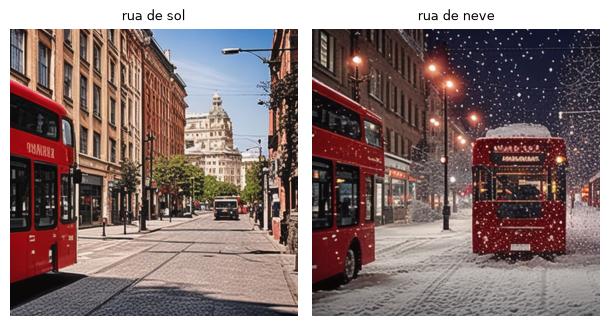

tamanho (512, 512)
canais do latente: 4
passos de treino: 1000
lado do latente: 64
escala do VAE: 0.18215


In [3]:
prompt = "a red city bus on a sunny street, photo"
foto_gerada = gerar(prompt, semente=0, n_passos=2)
noite = gerar("a red city bus on a snowy street at night, photo", semente=0, n_passos=2)
grade([foto_gerada, noite], ["rua de sol", "rua de neve"])
print("tamanho", foto_gerada.size)
print("canais do latente:", pipe.unet.config.in_channels)
print("passos de treino:", pipe.scheduler.config.num_train_timesteps)
print("lado do latente:", 512 // pipe.vae_scale_factor)
print("escala do VAE:", float(pipe.vae.config.scaling_factor))

In [4]:
# @title Correção automática (rode, não precisa ler)
from PIL import Image


def _pixels(img):
    return img.resize((16, 16)).tobytes()


VERIFICAR = {
    1: lambda r: int(r) == foto_gerada.size[0],
    2: lambda r: int(r) == pipe.unet.config.in_channels,
    3: lambda r: int(r) == pipe.scheduler.config.num_train_timesteps,
    4: lambda r: (
        isinstance(r, Image.Image)
        and r.size == (512, 512)
        and _pixels(r) != _pixels(foto_gerada)
    ),
    5: lambda r: int(r) == 512 // pipe.vae_scale_factor,
    6: lambda r: abs(float(r) - float(pipe.vae.config.scaling_factor)) < 1e-4,
}

_acertos = {}


def conferir(n, resposta):
    if resposta is None:
        print(f"Exercício {n}: ainda sem resposta.")
        return
    try:
        certo = bool(VERIFICAR[n](resposta))
    except Exception as erro:
        certo = False
        print(f"  (a verificação deu erro: {erro})")
    _acertos[n] = certo
    print(f"Exercício {n}: " + ("✅ certo!" if certo else "❌ ainda não. Releia o enunciado e tente de novo."))


def placar():
    print(f"{sum(_acertos.values())} de {len(VERIFICAR)} exercícios certos.")

## Sua vez

Gere de novo o mesmo prompt, com semente 4 e 1 passo. A resposta é a imagem. Ela precisa ter 512×512 e não pode ser a mesma `foto_gerada`.

*Dica:* gerar(prompt, semente=4, n_passos=1) devolve uma imagem PIL.

Troque o `None` pela sua resposta e rode a célula.

In [5]:
resposta = None

conferir(4, resposta)

Exercício 4: ainda sem resposta.


## Uma solução

Compare com o que você fez. Existem outros caminhos certos: o que vale é a `conferir` aprovar.

In [6]:
resposta = gerar(prompt, semente=4, n_passos=1)

conferir(4, resposta)

Exercício 4: ✅ certo!


## O que fica

Próximo: [Aula 3, exercício 5: Lado do latente](https://colab.research.google.com/github/naubergois/curso-clip-difusao-colab/blob/main/exercicios/aula3-exercicio5-lado-do-latente.ipynb).